<h1 style="text-align:center; font-weight:bold;">🧠 TP 1: Logic Gates with Perceptrons and MLP</h1>


# **Objectives**

 - Understand the functioning of a single-layer perceptron.

 - Implement the logical gate (OR) using a perceptron.

 - Identify the limitations of a perceptron for non-linearly separable problems.

 - Design a Multi-Layer Perceptron (MLP) to solve non-linear problems like XOR.

# **Part 1 : Single-Layer Perceptron Logic Gates with Keras**

In [ ]:

# Import Libraries

import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

In [ ]:

# Prepare Dataset

X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=np.float32)

# OR gate outputs
Y_or = np.array([[0],
                 [1],
                 [1],
                 [1]], dtype=np.float32)

In [ ]:

# Build Perceptron Model

def build_perceptron():
    model = Sequential() # Sequential is a Keras model type where layers are added one after another.
    model.add(Input(shape=(2,)))  # means each input sample has 2 features (X1 and X2 for logic gates).

    # activation='sigmoid' → squashes the output to [0,1], which is perfect for binary classification (0 or 1).
    model.add(Dense(1, activation='sigmoid'))

    # loss='binary_crossentropy' → suitable for binary outputs. Measures how far predictions are from real labels.
    # optimizer=Adam(learning_rate=0.01) → Adam optimizer with a custom learning rate. Adjusts weights during training.
    # metrics=['accuracy'] → tracks accuracy during training.

    model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=0.01), metrics=['accuracy'])
    return model

In [ ]:

# Train OR Gate

model_or = build_perceptron() # Create a fresh instance of the perceptron model
model_or.fit(X, Y_or, epochs=1000, verbose=1) # Train the model on the OR dataset for 1000 epochs (iterations)

predictions_or = model_or.predict(X) #Predict the raw output probabilities for the input data X
print("OR Gate Predictions (raw):\n", predictions_or) # Print raw output
print("OR Gate Predictions (0/1):\n", (predictions_or > 0.5).astype(int)) #Apply a 0.5 decision threshold to coutputs (0 or 1)



Epoch 1/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 550ms/step - accuracy: 0.2500 - loss: 1.2379
Epoch 2/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0000e+00 - loss: 1.2261
Epoch 3/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0000e+00 - loss: 1.2144
Epoch 4/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.0000e+00 - loss: 1.2028
Epoch 5/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.0000e+00 - loss: 1.1912
Epoch 6/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.0000e+00 - loss: 1.1797
Epoch 7/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.0000e+00 - loss: 1.1684
Epoch 8/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.0000e+00 - loss: 1.1571
Epoch 9/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.0000e+00 - loss: 1.1459
Epoch 10/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.0000e+00 - loss: 1.1348
Epoch 11/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.0000e+00 - loss: 1.1238
Epoch 12/1000
1/1 ━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
OR Gate Predictions (raw):
 [[0.23973389]
 [0.92544997]
 [0.88300234]
 [0.9966456 ]]
OR Gate Predictions (0/1):
 [[0]
 [1]
 [1]
 [1]]


In [ ]:

# Display Weights and Bias
#  weights : (w1, w2): How much weight the network assigns to inputs x1 and x2.
# Bias : b The offset added to shift the decision boundary line  so it correctly separates 0 from 1

weights_or, bias_or = model_or.layers[0].get_weights()
print("OR Gate Weights:", weights_or.flatten())
print("OR Gate Bias:", bias_or)



OR Gate Weights: [3.1753132 3.6729484]
OR Gate Bias: [-1.154139]


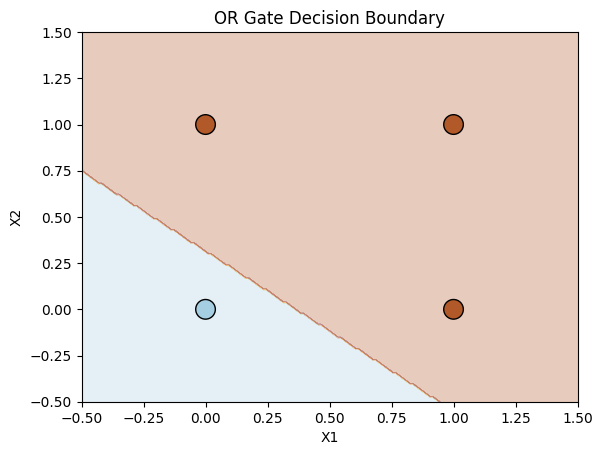

In [ ]:

# Visualize Decision Boundary

def plot_decision_boundary(model, X, Y, title):

    x_min, x_max = -0.5, 1.5
    y_min, y_max = -0.5, 1.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    grid = np.c_[xx.ravel(), yy.ravel()]
    probs = model.predict(grid, verbose=0)
    Z = (probs > 0.5).astype(int).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Paired)
    plt.scatter(X[:,0], X[:,1], c=Y.flatten(), s=200, edgecolors='k', cmap=plt.cm.Paired)
    plt.title(title)
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.show()



# OR Gate Visualization
plot_decision_boundary(model_or, X, Y_or, "OR Gate Decision Boundary")


# **Part 2 : Limitiations of Single-layer Perceptron**
- Single-layer perceptrons can model linearly separable functions like AND, OR.
- The sigmoid activation outputs probability; threshold >0.5 gives final logic output.
- The decision boundary shows how the perceptron classifies inputs.
- Single perceptrons cannot solve XOR (non-linearly separable).
- Weights and biases determine how inputs are combined to produce outputs.

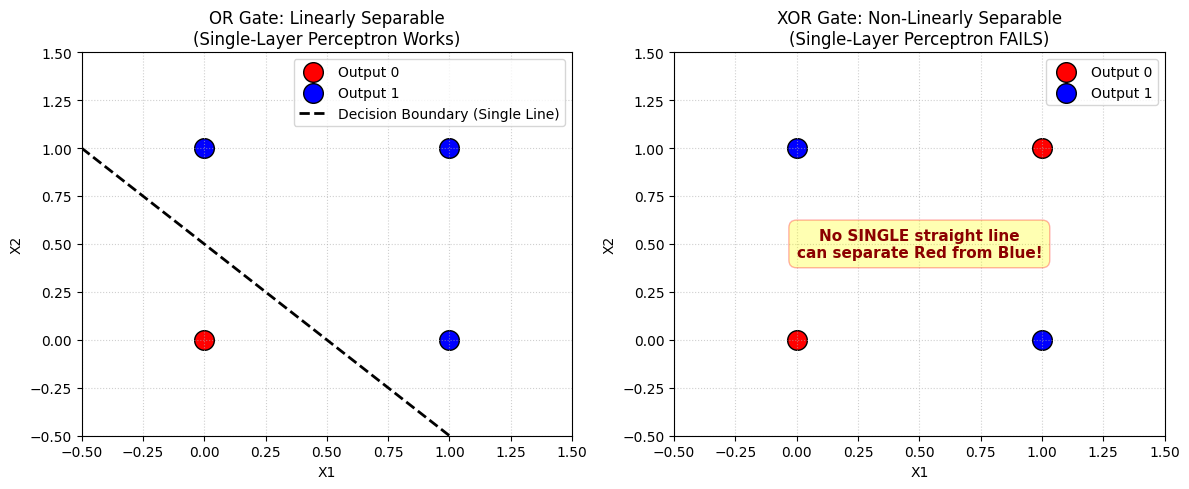

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create figure with two subplots side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Common coordinates for 2D binary inputs
inputs = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

# --------------------------------------------------
# Subplot 1: OR Gate (Linearly Separable)
# --------------------------------------------------
# Labels: (0,0) -> 0; all others -> 1
or_outputs = np.array([0, 1, 1, 1])

# Plot points
ax1.scatter(
    inputs[or_outputs == 0, 0],
    inputs[or_outputs == 0, 1],
    color="red",
    s=200,
    edgecolors="k",
    label="Output 0",
)
ax1.scatter(
    inputs[or_outputs == 1, 0],
    inputs[or_outputs == 1, 1],
    color="blue",
    s=200,
    edgecolors="k",
    label="Output 1",
)

# Single linear decision boundary line: x1 + x2 - 0.5 = 0  =>  x2 = -x1 + 0.5
x_vals = np.linspace(-0.5, 1.5, 100)
ax1.plot(
    x_vals,
    -x_vals + 0.5,
    "k--",
    linewidth=2,
    label="Decision Boundary (Single Line)",
)

ax1.set_title("OR Gate: Linearly Separable\n(Single-Layer Perceptron Works)")
ax1.set_xlabel("X1")
ax1.set_ylabel("X2")
ax1.set_xlim([-0.5, 1.5])
ax1.set_ylim([-0.5, 1.5])
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend(loc="upper right")

# --------------------------------------------------
# Subplot 2: XOR Gate (Non-Linearly Separable)
# --------------------------------------------------
# Labels: (0,0),(1,1) -> 0; (0,1),(1,0) -> 1
xor_outputs = np.array([0, 1, 1, 0])

# Plot points
ax2.scatter(
    inputs[xor_outputs == 0, 0],
    inputs[xor_outputs == 0, 1],
    color="red",
    s=200,
    edgecolors="k",
    label="Output 0",
)
ax2.scatter(
    inputs[xor_outputs == 1, 0],
    inputs[xor_outputs == 1, 1],
    color="blue",
    s=200,
    edgecolors="k",
    label="Output 1",
)

# Text annotation explaining why a single line fails
ax2.text(
    0.5,
    0.5,
    "No SINGLE straight line\ncan separate Red from Blue!",
    color="darkred",
    fontsize=11,
    fontweight="bold",
    ha="center",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.5", facecolor="yellow", alpha=0.3, edgecolor="red"
    ),
)

ax2.set_title("XOR Gate: Non-Linearly Separable\n(Single-Layer Perceptron FAILS)")
ax2.set_xlabel("X1")
ax2.set_ylabel("X2")
ax2.set_xlim([-0.5, 1.5])
ax2.set_ylim([-0.5, 1.5])
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("perceptron_limitations_part2.png", dpi=300)
plt.show()

# **Part 3 : Solving XOR with a Multi-Layer Perceptron (MLP)**

### 🎯 Objectives
- Understand why a single-layer perceptron cannot solve XOR.
- Design and train a Multi-Layer Perceptron (MLP) to solve XOR.
- Visualize and analyze the decision boundary of the MLP.

---

## 🔹 Task Instructions

1. **Design an MLP**
   - Include **at least one hidden layer**.
   - Decide on the **number of neurons** and the **activation function** for each layer.
   
2. **Train the MLP**
   - Use the XOR dataset:
     ```
     Inputs: [[0,0], [0,1], [1,0], [1,1]]
     Outputs: [[0], [1], [1], [0]]
     ```
   - Train the network until it correctly predicts all XOR outputs.

3. **Verify the predictions**
   - Check that the MLP outputs the **correct values** for all inputs.

4. **Visualize the decision boundary**
   - Compare the MLP boundary to the single-layer perceptron.
   - Observe how the hidden layer allows the network to separate non-linear regions.

---

## ❓ Final Question
- Explain **why adding a hidden layer allows the network to solve XOR**.
- Discuss how this **overcomes the limitations** of a single-layer perceptron.


In [ ]:

# Prepare XOR Dataset

X = np.array([[0,0],
              [0,1],
              [1,0],
              [1,1]], dtype=np.float32)

Y_xor = np.array([[0],
                 [1],
                 [1],
                 [0]], dtype=np.float32)


In [ ]:

# Build MLP Model

def build_mlp():
    model = Sequential()
    model.add(Input(shape=(2,)))

    # Hidden Layer: 8 neurons with ReLU activation to handle non-linearity
    model.add(Dense(8, activation='relu'))

    # Output Layer: 1 neuron with Sigmoid activation for binary output [0, 1]
    model.add(Dense(1, activation='sigmoid'))

    model.compile(loss='binary_crossentropy',
                  optimizer=Adam(learning_rate=0.01),
                  metrics=['accuracy'])
    return model

In [ ]:

# Train the MLP

model_xor = build_mlp()
model_xor.fit(X, Y_xor, epochs=1000, verbose=0)

In [ ]:

# Verify Predictions

predictions_xor = model_xor.predict(X)
print("XOR Predictions (raw probabilities):\n", predictions_xor)
print("XOR Predictions (0/1 binary output):\n", (predictions_xor > 0.5).astype(int))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
XOR Predictions (raw probabilities):
 [[0.00232075]
 [0.99779886]
 [0.99777544]
 [0.00220279]]
XOR Predictions (0/1 binary output):
 [[0]
 [1]
 [1]
 [0]]


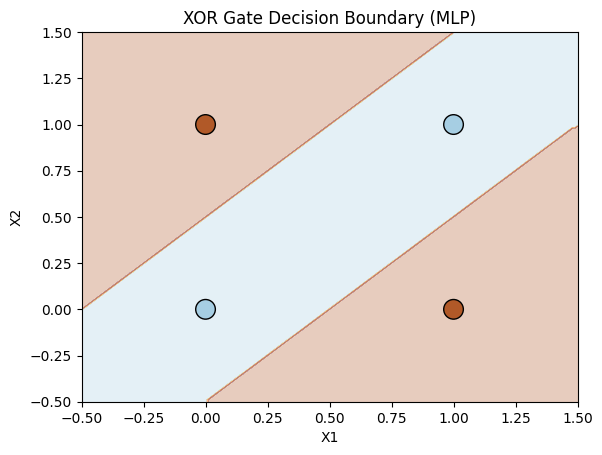

In [ ]:

# Visualize Decision Boundary

plot_decision_boundary(model_xor, X, Y_xor, "XOR Gate Decision Boundary (MLP)")